# 10 · Question Answering Chatbot: NewsBot (Module V)

**Theory.** *Extractive QA* answers a question by selecting a span of text from a document. Because
a reader model can only read a few hundred tokens at a time, open-domain QA is done in two stages:
a **retriever** finds a few candidate passages (here TF-IDF cosine over ~120-word chunks), then a
**reader** (DistilBERT fine-tuned on SQuAD) predicts, for every token, how likely it is to be the
answer's *start* and *end*. The best span is the one with the highest start + end score. A confidence
threshold lets the bot say "I don't know" instead of guessing.

**What is rule-based:** the *intent router* (`NewsBot.chat`) is plain regular expressions ("summarize
article N", "who is mentioned in article N", "what topic is …"). It does not learn anything. Only the
retriever statistics and the reader are data-driven.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import src.utils  # FIRST: cache folders

import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transformers

from src.utils import DATA, MODELS, ROOT, get_device
from src.data import load
from src.qa import NewsBot, chunk_articles
from src.evaluate import exact_match, save_results, token_f1

transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)

/Users/mihirmandavia/nlp-news/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Build NewsBot on all 2,089 BBC articles

In [2]:
bbc = load("bbc")
t = time.perf_counter()
bot = NewsBot(bbc, entities=pd.read_parquet(DATA / "entities.parquet"),
              classifier=joblib.load(MODELS / "tfidf_lr.joblib"), device=get_device(), threshold=0.2)
print(f"start-up {time.perf_counter() - t:.1f}s | {len(bot.retriever.passages):,} passages "
      f"(120 words, 40-word overlap) | TF-IDF vocab {len(bot.retriever.vec.vocabulary_):,} | "
      f"reader on {bot.reader.device}")

start-up 3.7s | 9,937 passages (120 words, 40-word overlap) | TF-IDF vocab 35,517 | reader on mps


## Chat demo: one message per intent

In [3]:
demo = ["Who did Rafael Nadal beat in the Davis Cup final?",
        "summarize article 1744",
        "who is mentioned in article 109",
        "what topic is article 1012",
        "what topic is this: The striker scored twice as United won the derby.",
        "Who won the 2018 FIFA World Cup?"]
for msg in demo:
    r = bot.chat(msg)
    extra = f"  (confidence {r['confidence']}, article {r['article_id']} [{r['category']}] {r['title']})" \
        if r["intent"] == "question" else ""
    print(f"> {msg}\n  [{r['intent']}] {r['answer']}{extra}\n")

> Who did Rafael Nadal beat in the Davis Cup final?
  [question] Andy Roddick  (confidence 0.8541, article 596 [sport] Nadal puts Spain 2-0 up)



> summarize article 1744
  [summarize] The US budget deficit is set to hit a worse-than-expected $368bn (£197bn) this year, officials said on Tuesday. The cost of military operations still needs to be factored in, with analysts saying the deficit could end up a further $100bn in the red. The budget deficit hit a record $412bn in the 12 months to 30 September 2004, after reaching $377bn in the previous fiscal year.

> who is mentioned in article 109
  [entities] Johnson, Ken Livingstone, Livingstone, Boris Johnson, Tony Blair, Mr Blair, Ken Bigley, Blair, Labour, Bigley

> what topic is article 1012
  [topic] Sci/Tech (96%) (BBC label: tech)

> what topic is this: The striker scored twice as United won the derby.
  [topic] Sports (83%)

> Who won the 2018 FIFA World Cup?
  [question] Mia Hamm  (confidence 0.3462, article 706 [sport] Henry tipped for Fifa award)



## Evaluation on 40 hand-written questions
`docs/qa_pairs.json`: 30 answerable questions drafted from real BBC passages (answers copied verbatim)
plus 10 questions the corpus cannot answer. ⚠️ Drafted by the AI assistant, so review them.

Metrics: **hit@k** = the correct article is among the top-k retrieved passages. **EM** = exact match
after SQuAD normalisation. **F1** = word-overlap F1 with the best acceptable answer.

In [4]:
qa = json.loads((ROOT / "docs" / "qa_pairs.json").read_text())
rows = []
for item in qa["answerable"]:
    r = bot.ask(item["question"])
    rows.append({"question": item["question"], "gold": item["answers"][0], "pred": r["best_guess"],
                 "confidence": r["confidence"], "EM": exact_match(r["best_guess"], item["answers"]),
                 "F1": token_f1(r["best_guess"], item["answers"]),
                 "hit@1": r["retrieved_article_ids"][0] == item["article_id"],
                 "hit@3": item["article_id"] in r["retrieved_article_ids"], "answerable": True})
for q in qa["unanswerable"]:
    r = bot.ask(q)
    rows.append({"question": q, "gold": None, "pred": r["best_guess"], "confidence": r["confidence"],
                 "answerable": False})
ev = pd.DataFrame(rows)
ans = ev[ev.answerable]
print(f"retrieval hit@1 {ans['hit@1'].mean():.3f}  hit@3 {ans['hit@3'].mean():.3f}  | "
      f"end-to-end reader EM {ans.EM.mean():.3f}  F1 {ans.F1.mean():.3f}  (n={len(ans)})")
ans.drop(columns=["answerable"])

retrieval hit@1 0.833  hit@3 0.933  | end-to-end reader EM 0.767  F1 0.802  (n=30)


,question,gold,pred,confidence,EM,F1,hit@1,hit@3
0,Which Aberdeen-based consultancy entered Iraq in 2003?,Blackwatch Petroleum Services,Blackwatch Petroleum Services,0.9946,1.0,1.000000,True,True
1,Who chairs the working party on Russia's WTO membership?,Stefan Johannesson,Ambassador Stefan Johannesson,0.5146,1.0,1.000000,True,True
2,By how much did UK house prices rise in February according to the Nationwide?,0.5%,0.8%,0.9843,0.0,0.000000,True,True
3,By how much did the IEA raise its estimate of 2005 oil demand growth?,"80,000 barrels a day","80,000 barrels a day to 84 million barrels a day",0.6977,0.0,0.545455,True,True
4,Who is the government's chief witness in the case against Bernie Ebbers?,Scott Sullivan,Mr Sullivan,0.9101,1.0,1.000000,True,True
5,How large is the US budget deficit expected to be this year?,$368bn,$368bn (£197bn),0.4467,1.0,1.000000,False,True
6,How much are US box office ticket sales expected to reach this year?,$9.4 billion,$9.4 billion,0.9624,1.0,1.000000,True,True
7,Where was the science conference on the effect of the CSI shows held?,Washington DC,Washington DC,0.9617,1.0,1.000000,True,True
8,Which play did Uganda's authorities ban?,The Vagina Monologues,The Vagina Monologues,0.9747,1.0,1.000000,True,True
9,Which film did children vote best film at the children's Bafta awards?,Shrek 2,Shrek 2,0.9882,1.0,1.000000,True,True


### Reader alone: given the correct passage
To separate the two stages, we also give the reader the gold passage directly (the passage of the
correct article that contains the answer). The gap between this and end-to-end = errors caused by retrieval.

In [5]:
passages = chunk_articles(bbc)
oracle = []
for item in qa["answerable"]:
    gold_p = next(p["text"] for p in passages
                  if p["article_id"] == item["article_id"] and item["answers"][0] in p["text"])
    span = bot.reader.best_span(item["question"], [gold_p])
    oracle.append({"EM": exact_match(span["answer"], item["answers"]),
                   "F1": token_f1(span["answer"], item["answers"]), "pred": span["answer"]})
oracle = pd.DataFrame(oracle)
print(f"reader with gold passage: EM {oracle.EM.mean():.3f}  F1 {oracle.F1.mean():.3f}")

reader with gold passage: EM 0.933  F1 0.952


### Errors, one by one

In [6]:
wrong = ans[ans.F1 < 1].assign(oracle_pred=oracle.pred[ans.F1.values < 1].values)
wrong[["question", "gold", "pred", "oracle_pred", "confidence", "F1", "hit@3"]]

,question,gold,pred,oracle_pred,confidence,F1,hit@3
2,By how much did UK house prices rise in February according to the Nationwide?,0.5%,0.8%,0.5%,0.9843,0.000000,True
3,By how much did the IEA raise its estimate of 2005 oil demand growth?,"80,000 barrels a day","80,000 barrels a day to 84 million barrels a day","80,000 barrels a day to 84 million barrels a day",0.6977,0.545455,True
15,Who is Pakistan's High Commissioner to Britain?,Dr Maleeha Lodhi,General Musharraf,General Musharraf,0.3130,0.000000,True
16,How many members does the union Amicus have?,1.2 million,"20,000",1.2 million,0.9921,0.000000,True
19,Which tournament did Juan Carlos Ferrero win in 2003?,French Open,Dubai Open,French Open,0.9103,0.500000,True
22,Which number eight was dropped from France's squad to face Ireland?,Imanol Harinordoquy,Gregory Lamboley,Imanol Harinordoquy,0.9025,0.000000,True
29,Which EU member state rejected the software patent directive twice?,Poland,EC President José Manuel Barroso told the President of the European Parliament,Poland,0.1117,0.000000,True


**What the errors show.**
- **Most errors are distractor passages, not retrieval misses.** In every wrong case the right article
  *was* in the top 3 (hit@3 = True), and the reader alone gets 5 of the 7 right when given the gold
  passage ("0.8%" instead of "0.5%", "Dubai Open" instead of "French Open"). Start/end logits are not
  calibrated across passages, so a confident-looking span in a similar article can win. A fix would be
  to re-rank by retrieval score plus reader score, or pass only the top-1 passage when it is clearly best.
- **Span boundary:** "80,000 barrels a day *to 84 million barrels a day*" is too long (partial F1).
- **Reader error:** "Who is Pakistan's High Commissioner?" → "General Musharraf", even from the gold
  passage: the reader picks the most prominent name.
- Also visible in the demo: "who is mentioned in article 109" lists *Labour* as a person, the spaCy
  NER error already seen in nb04.

## Tuning the "I don't know" threshold
A question is handled **correctly** when (answerable) the bot answers with F1 ≥ 0.5, or (unanswerable)
the bot says "I don't know". We try every threshold and keep the best. Caveat: we tune and measure
on the same 40 questions, so the chosen threshold's score is optimistic.

best threshold ≈ 0.481 -> 75.0% of the 40 questions handled correctly (threshold 0: 62.5%)


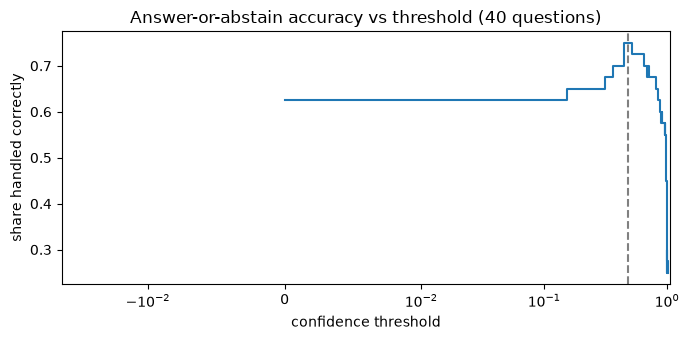

confidence, answerable questions  : median 0.966
confidence, unanswerable questions: median 0.563


,question,pred,confidence
30,Who won the 2018 FIFA World Cup?,Mia Hamm,0.3462
31,When was the first iPhone released?,11 March,0.3654
32,Who won the 2016 US presidential election?,Mr Blair,0.1525
33,In which year did the Brexit referendum take place?,2006,0.9577
34,Who is the founder of the company OpenAI?,Mikhail Khodorkovsky,0.9954
35,How many moons does Jupiter have?,four,0.8988
36,What is the name of Elon Musk's rocket company?,Rocket Baby Dolls,0.4446
37,Which team won the 2010 Champions League final?,Chelsea,0.6806
38,What is the boiling point of water on Mount Everest?,freezing them during devaluation,0.1190
39,Who directed the film Oppenheimer?,Nicole Kassell,0.9965


In [7]:
conf = ev.confidence.to_numpy()
good_answer = (ev.answerable & (ev.F1.fillna(0) >= 0.5)).to_numpy()
unanswerable = (~ev.answerable).to_numpy()
grid = np.unique(np.concatenate([[0.0], conf, [1.01]]))
acc = [np.mean(np.where(conf >= t, good_answer, unanswerable)) for t in grid]
best = int(np.argmax(acc))
# several thresholds can tie; take the midpoint between the best one and the next confidence value
threshold = float((grid[best] + grid[min(best + 1, len(grid) - 1)]) / 2) if best > 0 else 0.0
print(f"best threshold ≈ {threshold:.3f} -> {acc[best]:.1%} of the 40 questions handled correctly "
      f"(threshold 0: {acc[0]:.1%})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grid, acc, drawstyle="steps-post")
ax.axvline(threshold, ls="--", c="gray")
ax.set_xlabel("confidence threshold"); ax.set_ylabel("share handled correctly"); ax.set_xscale("symlog", linthresh=0.01)
ax.set_title("Answer-or-abstain accuracy vs threshold (40 questions)")
plt.tight_layout(); plt.show()

print("confidence, answerable questions  : median", round(float(np.median(conf[~unanswerable])), 3))
print("confidence, unanswerable questions: median", round(float(np.median(conf[unanswerable])), 3))
ev[~ev.answerable][["question", "pred", "confidence"]]

For an unanswerable question the reader still returns its best span from whatever was retrieved,
because it is forced to pick *something*. The reader was trained on SQuAD 1.1, which has no
unanswerable questions, and its confidence is relative *within one passage*. So some nonsense answers
get very high confidence ("Who directed Oppenheimer?" → a different director, "Who founded OpenAI?" →
Khodorkovsky). **No threshold can catch those**, which is why the best threshold handles only part
of the unanswerable set. A reader trained on SQuAD 2.0 (which has a "no answer" option) would do better.

In [8]:
bot.threshold = threshold
for msg in ["Who won the 2018 FIFA World Cup?", "Who is the head of Tiga?"]:
    r = bot.chat(msg)
    print(f"> {msg}\n  {r['answer']}  (confidence {r['confidence']})")

save_results("qa", {
    "n_passages": len(passages), "chunk_words": 120, "overlap_words": 40, "retriever": "TF-IDF (src/tfidf.py)",
    "reader": "distilbert-base-cased-distilled-squad", "n_answerable": len(ans), "n_unanswerable": int(unanswerable.sum()),
    "retrieval_hit_at_1": round(float(ans["hit@1"].mean()), 3), "retrieval_hit_at_3": round(float(ans["hit@3"].mean()), 3),
    "reader_em": round(float(ans.EM.mean()), 3), "reader_f1": round(float(ans.F1.mean()), 3),
    "oracle_reader_em": round(float(oracle.EM.mean()), 3), "oracle_reader_f1": round(float(oracle.F1.mean()), 3),
    "threshold": round(threshold, 4), "answer_or_abstain_accuracy": round(float(acc[best]), 3),
    "questions": ev.drop(columns=[]).to_dict("records"),
})

> Who won the 2018 FIFA World Cup?
  I don't know.  (confidence 0.3462)
> Who is the head of Tiga?
  Fred Hasson  (confidence 0.9947)
saved results/qa.json


PosixPath('/Users/mihirmandavia/nlp-news/results/qa.json')

## Viva notes
**Q1. Which part of the chatbot is rule-based?**
The intent router in `NewsBot.chat`: regular expressions for "summarize article N", "who is mentioned
in article N" and "what topic is …". Everything else goes to the QA pipeline. The QA part is
data-driven: TF-IDF statistics for retrieval and a SQuAD-trained DistilBERT reader.

**Q2. How is the answer span chosen?**
For each of the top-3 passages the reader outputs a start logit and an end logit per token. We score
every span (i, j) with j ≥ i and length ≤ 30 tokens as start[i] + end[j], and take the best over all
passages. Confidence = softmax(start)[i] × softmax(end)[j] within that passage.

**Q3. Why chunk articles with overlap?**
The reader has a 384-token window, and short passages make retrieval more precise. With a 40-word
overlap, an answer that falls on a chunk boundary is still whole in one of the two chunks.